 **Importing necessary libraries and data sets**

In [193]:
# importing necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# importing firing-rates and search-times data-set
firing_rates_data = pd.read_csv('/content/firing-rates-dataset.csv')      # Enter the firing-rates-dataset path here
search_times_data = pd.read_csv('/content/search-times-dataset.csv')      # Enter the search-times-dataset path here

 ***(1.1)*** **Creating Average Search delays array**

In [195]:
# selecting data starting from the 4th row (index 3)
search_times_data_selected = search_times_data.iloc[2:, :]

# converting numbers which are in str datatype to numeric data type
search_times_datanumeric = search_times_data_selected.apply(pd.to_numeric, errors = 'coerce')

# subtracting 328 from each data point
search_times_data_adjusted = search_times_datanumeric - 328

# computing mean for each column
means = search_times_data_adjusted.mean(axis = 0)

# converting means into numpy array and storing it in average_search_delays array
average_search_delays = np.array(means)

print(f"average_search_delays = {average_search_delays}")

average_search_delays = [ 883.77777778 1081.40277778  985.25       1009.13888889  275.26388889
  296.66666667  503.31944444  502.79166667  313.40277778  307.52777778
  218.55555556  251.95833333  818.33333333  615.23611111  309.40277778
  341.93055556  239.84722222  209.38888889]


 ***(1.2)*** **Creating Relative Entropy Distances array**

In [196]:
# Creating a list to compute relative entropy distances from the firing rates data set and
# storing it in divided_data variable

"""
In the divided_data, it have lists elemets with first element of sub list as odd ball and
second element as distracter image.(done for all 9 pairs of images and stored them in the
divide data). After this using relative_entropy_distances_calculator function to calculate
relative entropy distances and store it in an array
"""

divided_data = []
for i in range(0,18,2):
  column_data_1 = firing_rates_data.iloc[3:,i]
  column_data_2 = firing_rates_data.iloc[3:,i+1]
  numeric_array_1 = pd.to_numeric(column_data_1, errors = 'coerce').dropna().to_numpy()
  numeric_array_2 = pd.to_numeric(column_data_2, errors = 'coerce').dropna().to_numpy()
  divided_data.append([numeric_array_1,numeric_array_2])
  divided_data.append([numeric_array_2,numeric_array_1])

In [197]:
# function to calculate relative entropy distance
def relative_entropy_distances_calculator(data):
    oddball_array = data[0]
    distracter_array = data[1]
    N = len(oddball_array)
    sum = 0
    for n in range(N):
        if oddball_array[n] == 0 or distracter_array[n] == 0:
            continue
        else:
            sum += (oddball_array[n]) * np.log(oddball_array[n] / distracter_array[n]) - oddball_array[n] + distracter_array[n]

    return sum / N

# while calculating realtive entropy distance we are ignoring the rows which have atlest one 0

In [198]:
# creating relative entropy distance array
relative_entropy_distances = []
for data in divided_data:
  relative_entropy_distances.append(relative_entropy_distances_calculator(data))
relative_entropy_distances = np.array(relative_entropy_distances)
print(f"relative_entropy_distances = {relative_entropy_distances}")

relative_entropy_distances = [0.61889728 0.59952425 0.6467379  0.65287086 1.53102694 1.60608012
 1.08572811 1.05018939 1.35531009 1.37282817 1.62428541 1.85850732
 0.60189317 0.72086219 1.01858291 1.32680806 1.59739755 1.66837916]


 ***(1.3)*** **Creating l_1_distances array**

In [199]:
# function to calculate l_1_distances
def l_1_distances_calculator(data):
  odd_ball_array = data[0]
  distracter_array = data[1]
  N = len(odd_ball_array)
  sum = 0
  for i in range(N):
    sum+=abs(odd_ball_array[i]-distracter_array[i])
  return sum/N

In [200]:
# creating l_1_distance array
l_1_distances = []
for i in range(0,18,2):
  l_1_distances.append(l_1_distances_calculator(divided_data[i]))
  l_1_distances.append(l_1_distances_calculator(divided_data[i+1]))
l_1_distances = np.array(l_1_distances)
print(l_1_distances)

[2.77571577 2.77571577 3.19047873 3.19047873 4.74959241 4.74959241
 3.72925422 3.72925422 3.97588362 3.97588362 4.56493061 4.56493061
 2.95867731 2.95867731 3.71361603 3.71361603 5.3424157  5.3424157 ]


 ***(2.1)*** **Fitting a straight line passing through the origin, With relative entropy distances on the xaxis and inverse of average search delays on the yaxis**

Slope of best fit line: 0.0023563133896909246


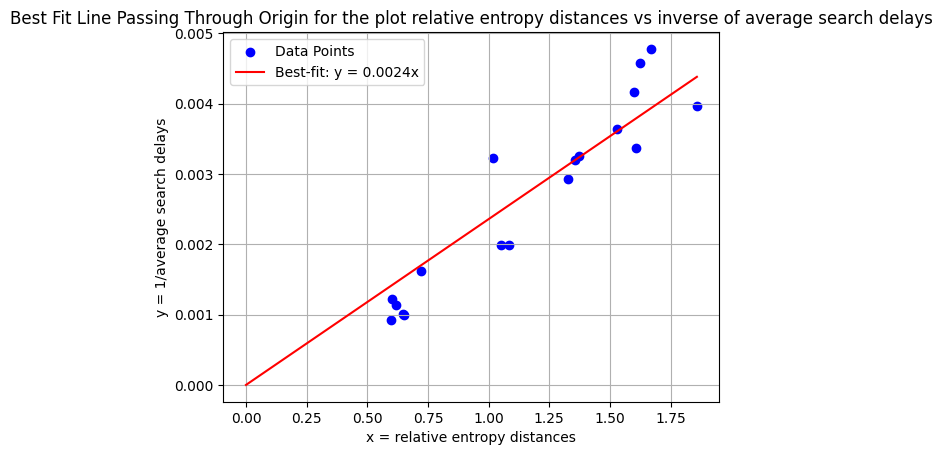

In [201]:
# data points (x,y)
x = relative_entropy_distances
y = 1/average_search_delays
# Computing the best-fit slope
m = np.sum(x * y) / np.sum(x**2)
print(f"Slope of best fit line: {m}")
# Generate fitted line
x_fit = np.linspace(0, max(x), 100)
y_fit = m * x_fit  # Line equation

# Plot the points and the best-fit line
plt.scatter(x, y, color='blue', label='Data Points')
plt.plot(x_fit, y_fit, color='red', label=f'Best-fit: y = {m:.4f}x')
plt.xlabel('x = relative entropy distances')
plt.ylabel('y = 1/average search delays')
plt.legend()
plt.title('Best Fit Line Passing Through Origin for the plot relative entropy distances vs inverse of average search delays')
plt.grid()
plt.show()

 ***(2.2)*** **Fitting a straight line passing through the origin, With l1 distances on the xaxis and inverse of average search delays on the yaxis.**

Slope of best fit line: 0.0007175217660089358


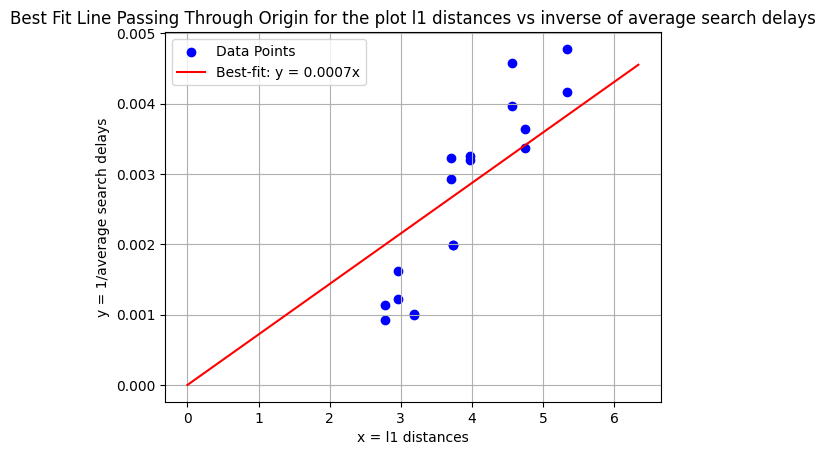

In [202]:
# data points (x,y)
x = l_1_distances
y = 1/average_search_delays
# Computing the best-fit slope
m = np.sum(x * y) / np.sum(x**2)
print(f"Slope of best fit line: {m}")
# Generate fitted line
x_fit = np.linspace(0, max(x)+1, 100)
y_fit = m * x_fit  # Line equation

# Plot the points and the best-fit line
plt.scatter(x, y, color='blue', label='Data Points')
plt.plot(x_fit, y_fit, color='red', label=f'Best-fit: y = {m:.4f}x')
plt.xlabel('x = l1 distances')
plt.ylabel('y = 1/average search delays')
plt.legend()
plt.title('Best Fit Line Passing Through Origin for the plot l1 distances vs inverse of average search delays')
plt.grid()
plt.show()

 ***(3.1)*** **Plotting the standard deviation of the search delays against their means for random half of the columns and estimating the shape parameter of gamma distribution.**

In [203]:
# creating mean_search_delays array and std_search_delays array

# Randomly selecting half of the columns to estimate the shape parameter of gamma distribution
selected_columns_for_shape_parameter= np.random.choice(search_times_data_adjusted.columns, size=len(search_times_data_adjusted.columns) // 2, replace=False)

# Extracting the selected columns from the DataFrame
selected_data_for_shape_parameter = search_times_data_adjusted[selected_columns_for_shape_parameter]

# Computing means and standard deviations of selected columns
means = selected_data_for_shape_parameter.mean(axis=0)
standard_deviations = selected_data_for_shape_parameter.std(axis=0)

# storing means in mean_search_delays array and storing standard_deviations in std_search_delays array
mean_search_delays = np.array(means)
std_search_delays = np.array(standard_deviations)

The shape parameter of gamma distribution(a) = 2.3928370814108946


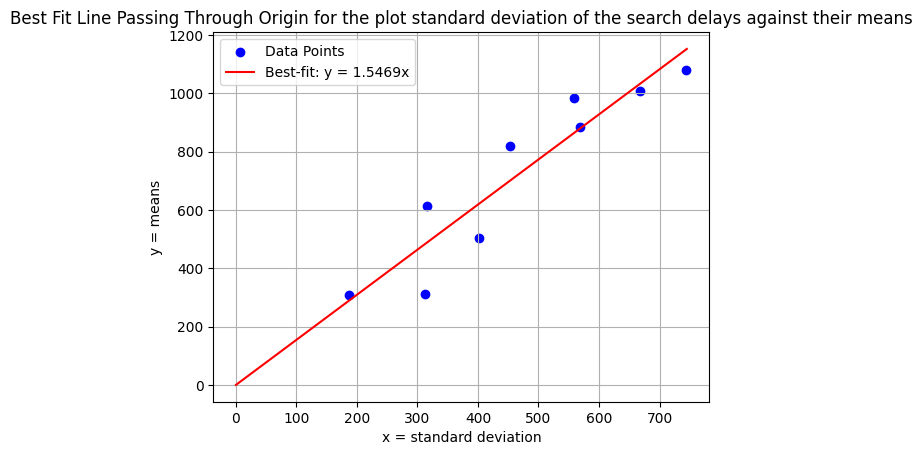

In [204]:
'''
for gamma distribution mean = square root of shape times standard deviation.
plotting mean on y-axis and standard deviation on x-axis and finding best fit line and it's slope.
shape parameter(a) = square of slope
'''
x = std_search_delays
y = mean_search_delays
# Computing the best-fit slope
m = np.sum(x * y) / np.sum(x**2)

# computing and printing the shape parameter(a)
a = m**2
print(f"The shape parameter of gamma distribution(a) = {a}")

# Generate fitted line
x_fit = np.linspace(0, max(x)+1, 100)
y_fit = m * x_fit  # Line equation

# Plot the points and the best-fit line
plt.scatter(x, y, color='blue', label='Data Points')
plt.plot(x_fit, y_fit, color='red', label=f'Best-fit: y = {m:.4f}x')
plt.xlabel('x = standard deviation')
plt.ylabel('y = means')
plt.legend()
plt.title('Best Fit Line Passing Through Origin for the plot standard deviation of the search delays against their means')
plt.grid()
plt.show()

 ***(3.2)*** **Estimating Rate parameter from the half columns of remaing columns that not contributed in the estimating of shape parameter**

In [205]:
"""
From the each column that did not contribute the shape parameter,
we are selecting half values randomly and making a data frame to calculate the rate parameter(b)
"""

# first_half_data is used to compute the rate parameter(b)
remaining_columns = list(set(search_times_data_adjusted.columns) - set(selected_columns_for_shape_parameter))
first_half_data = []
second_half_data = []
for col in remaining_columns:
  sampled_rows = search_times_data_adjusted[col].sample(frac = 0.5, replace = False)
  first_half_data.append(sampled_rows)
  remaining_rows = search_times_data_adjusted[col].drop(sampled_rows.index)
  second_half_data.append(remaining_rows.values)

In [206]:
# creating mean_search_delays array and std_search_delays array for selected_data_for_rate_parameter

# creating selected_data_for_rate_parameter from the first_half_data
selected_data_for_rate_parameter = pd.DataFrame({col: data.values for col, data in zip(remaining_columns, first_half_data)})

# computing means and standard deviations for each column of selected_data_for_rate_parameter
means = selected_data_for_rate_parameter.mean(axis=0)
standard_deviations = selected_data_for_rate_parameter.std(axis=0)

# storing means and standard deviations in mean_search_delays_for_b and std_search_delays_for_b arrays respectively
mean_search_delays_for_b = np.array(means)
std_search_delays_for_b = np.array(standard_deviations)

The rate parameter of gamma distribution (b) = 0.007044520258812129


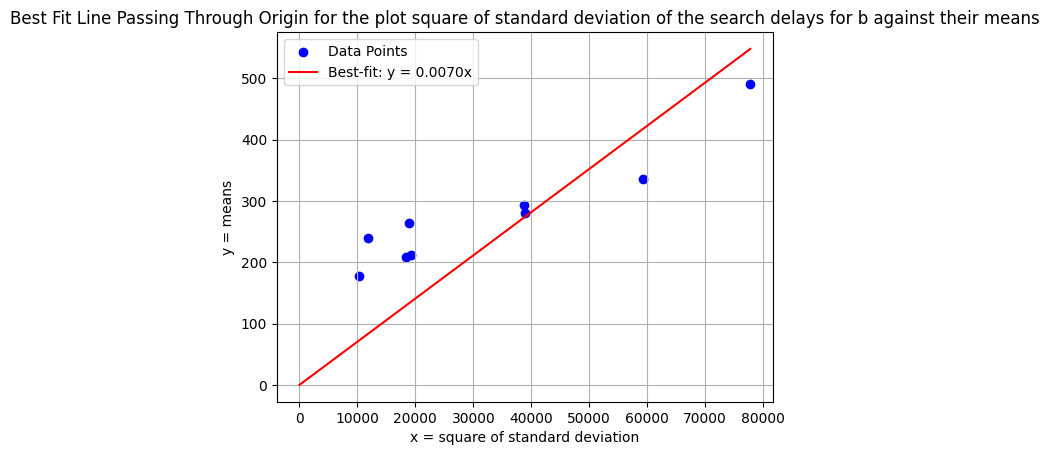

In [207]:
'''
for gamma distribution mean = rate parameter times square of standard deviation.
plotting mean on y-axis and square of standard deviation on x-axis and finding best fit line and it's slope.
rate parameter(b) = slope
'''
x = std_search_delays_for_b**2
y = mean_search_delays_for_b
# Computing the best-fit slope
m = np.sum(x * y) / np.sum(x**2)

# computing and printing the rate parameter(b)
b = m
print(f"The rate parameter of gamma distribution (b) = {b}")

# Generate fitted line
x_fit = np.linspace(0, max(x)+1, 100)
y_fit = m * x_fit  # Line equation

# Plot the points and the best-fit line
plt.scatter(x, y, color='blue', label='Data Points')
plt.plot(x_fit, y_fit, color='red', label=f'Best-fit: y = {m:.4f}x')
plt.xlabel('x = square of standard deviation')
plt.ylabel('y = means')
plt.legend()
plt.title('Best Fit Line Passing Through Origin for the plot square of standard deviation of the search delays for b against their means')
plt.grid()
plt.show()

 ***(3.3)*** **Plotting empirical cdf values,theoretical cdf values and printing Kolmogorov-Smirov (ks) test static**

Kolmogorov-Smirov (ks) test static = 0.17172930162874617


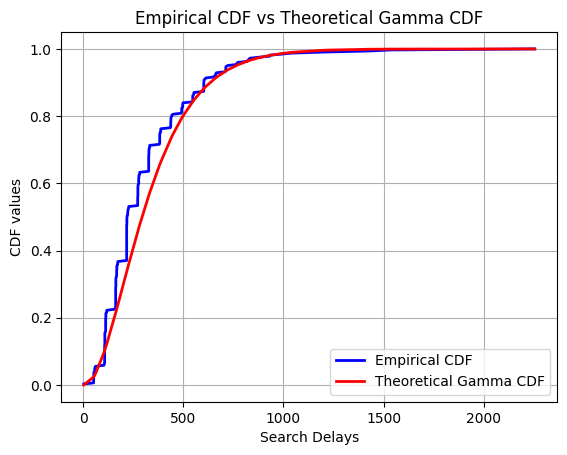

In [208]:
from scipy.stats import gamma  # Import gamma function
# Concatenating the second half data for estimation to create serch_delays array
search_delays = np.concatenate(second_half_data)

# computing Empirical CDF
x_values = np.sort(search_delays)
ecdf_values = np.arange(1, len(x_values) + 1) / len(x_values)

# Defining shape and rate parameter
shape_parameter = a
rate_parameter = b

# Computing theoretical Gamma CDF
gamma_cdf_values = gamma.cdf(x_values, a=shape_parameter, scale=1/rate_parameter)

# Computing and Printing Kolmogorov-Smirov (ks) test static
ks_static = np.max(np.abs(ecdf_values - gamma_cdf_values))
print(f"Kolmogorov-Smirov (ks) test static = {ks_static}")

# Plotting Empirical CDF vs Theoretical Gamma CDF
plt.plot(x_values, ecdf_values, label = "Empirical CDF", color = "blue", linewidth = 2)
plt.plot(x_values, gamma_cdf_values, label = "Theoretical Gamma CDF", color = "red", linewidth = 2)
plt.xlabel("Search Delays")
plt.ylabel("CDF values")
plt.title("Empirical CDF vs Theoretical Gamma CDF")
plt.legend()
plt.grid(True)
plt.show()